# 📘 Predicting Housing Prices Using Machine Learning

This notebook builds a machine learning model to predict housing prices using Linear Regression from scikit-learn.

## 📦 Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 📂 Load the Dataset

In [2]:
df = pd.read_csv('assignment1_usa_housing.csv')
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [3]:
print(f'Total number of records: {df.shape[0]}')
print(f'Number of missing fields:\n{df.isnull().sum()}')

Total number of records: 5000
Number of missing fields:
Avg. Area Income                0
Avg. Area House Age             0
Avg. Area Number of Rooms       0
Avg. Area Number of Bedrooms    0
Area Population                 0
Price                           0
Address                         0
dtype: int64


## 📊 Visualize the Dataset

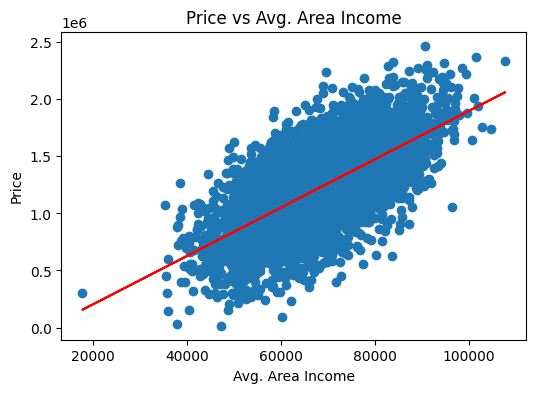

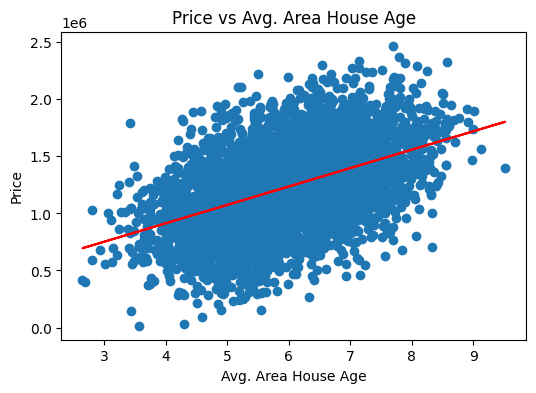

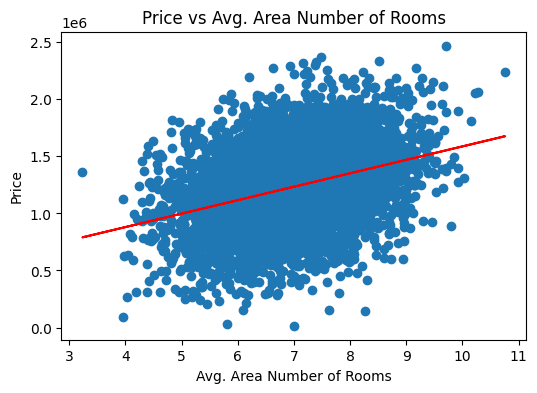

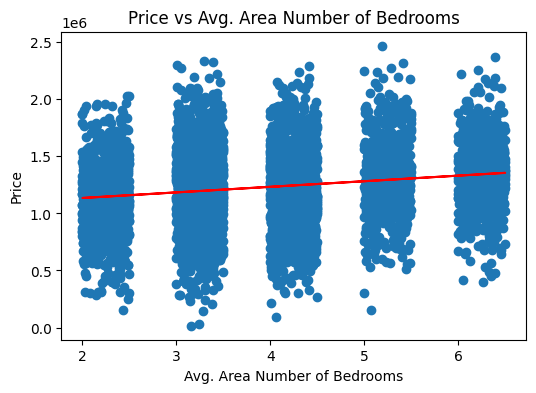

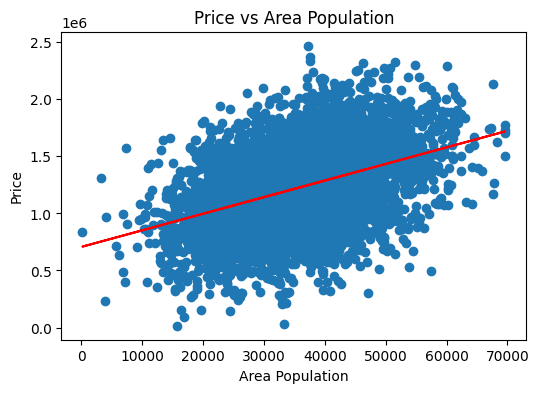

In [4]:
# Columns to plot (exclude Price and Address)
columns_to_plot = [col for col in df.columns if col not in ["Price", "Address"]]

# Optional: create directory to save plots
# output_dir = "price_scatterplots"
# os.makedirs(output_dir, exist_ok=True)

# Generate scatterplots with red trend lines
for col in columns_to_plot:
    plt.figure(figsize=(6, 4))
    
    # Scatter plot
    plt.scatter(df[col], df["Price"])
    
    # Trend line
    x = df[col]
    y = df["Price"]
    m, b = np.polyfit(x, y, 1)
    plt.plot(x, m * x + b, color="red")
    
    # Labels and title
    plt.xlabel(col)
    plt.ylabel("Price")
    plt.title(f"Price vs {col}")
    
    # Save plot
    # filename = f"price_vs_{col.replace(' ', '_').lower()}.png"
    # plt.savefig(os.path.join(output_dir, filename), bbox_inches="tight")
    
    plt.show()
    plt.close()

## 🧹 Data Preparation

In [5]:
X = df.drop(columns=['Price', 'Address'])
y = df['Price']

## ✂️ Train-Test Split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 🤖 Train the Model

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


## 🔮 Make Predictions

In [8]:
y_pred = model.predict(X_test)

## 📊 Model Evaluation

In [9]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'Mean Absolute Error (MAE): {mae:.2f}')
print(f'Root Mean Squared Error (RMSE): {rmse:.2f}')
print(f'R-squared (R2): {r2:.3f}')

print(f'\nIntercept: {model.intercept_}')

print(f'Coefficients:\n{pd.Series(model.coef_, index=X.columns)}')

Mean Absolute Error (MAE): 80879.10
Root Mean Squared Error (RMSE): 100444.06
R-squared (R2): 0.918

Intercept: -2635072.900933357
Coefficients:
Avg. Area Income                    21.652206
Avg. Area House Age             164666.480722
Avg. Area Number of Rooms       119624.012232
Avg. Area Number of Bedrooms      2440.377611
Area Population                     15.270313
dtype: float64


In [10]:
# Fit Ordinary Least Squares (OLS) regression
model = sm.OLS(y, X).fit()

# Display p-values
print(model.pvalues)

Avg. Area Income                3.834958e-279
Avg. Area House Age              2.421604e-65
Avg. Area Number of Rooms        3.228740e-03
Avg. Area Number of Bedrooms     1.925386e-01
Area Population                 1.292492e-127
dtype: float64


## 📊 Feature Coefficients & P-Values
| Feature                      | Coefficient    | P-value    |
| ---------------------------- | -------------- | ---------- |
| Avg. Area House Age          | **164,666.48** | **~0.000** |
| Avg. Area Number of Rooms    | **119,624.01** | **~0.000** |
| Avg. Area Number of Bedrooms | **2,440.38**   | **0.193**  |
| Avg. Area Income             | **21.65**      | **~0.000** |
| Area Population              | **15.27**      | **~0.000** |


## ✅ Conclusion

The Linear Regression model explains about 92% of the variance in housing prices, making it a strong baseline model for this dataset.